<a href="https://colab.research.google.com/github/anujjakhotiya/AI-DL_2026/blob/main/2403A51016_AIDL_LabTest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kagglehub

import kagglehub
import os

# Download Cats vs Dogs dataset
dataset_path = kagglehub.dataset_download(
    "tongpython/cat-and-dog"
)

print("Dataset downloaded to:", dataset_path)

# Display folders
for root, dirs, files in os.walk(dataset_path):
    if dirs:
        print(root, dirs[:5])

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Dataset downloaded to: /kaggle/input/cat-and-dog
/kaggle/input/cat-and-dog ['test_set', 'training_set']
/kaggle/input/cat-and-dog/test_set ['test_set']
/kaggle/input/cat-and-dog/test_set/test_set ['dogs', 'cats']
/kaggle/input/cat-and-dog/training_set ['training_set']
/kaggle/input/cat-and-dog/training_set/training_set ['dogs', 'cats']


In [ ]:
import os

train_path = None
test_path = None

for root, dirs, files in os.walk(dataset_path):

    folder_names = [d.lower() for d in dirs]

    if "cats" in folder_names and "dogs" in folder_names:

        if "training_set" in root.lower():
            train_path = root

        elif "test_set" in root.lower():
            test_path = root

print("Train Path:", train_path)
print("Test Path:", test_path)

Train Path: /kaggle/input/cat-and-dog/training_set/training_set
Test Path: /kaggle/input/cat-and-dog/test_set/test_set


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_data = datasets.ImageFolder(
    train_path,
    transform=train_transform
)

test_data = datasets.ImageFolder(
    test_path,
    transform=test_transform
)

classes = train_data.classes

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=32, shuffle=False
)

print("Classes:", classes)
print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Classes: ['cats', 'dogs']
Training images: 8005
Testing images: 2023


In [ ]:
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze pre-trained layers
for param in model.parameters():
    param.requires_grad = False

# Replace final layer
model.fc = nn.Linear(
    model.fc.in_features,
    len(classes)
)

model = model.to(device)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 108MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [ ]:

from torch.utils.data import Subset
import random

random.seed(42)

indices = random.sample(
    range(len(train_data)),
    2000
)

small_train_data = Subset(train_data, indices)

train_loader = DataLoader(
    small_train_data,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

# Train only the final layer
epochs = 3

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = running_loss / len(train_loader)

    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch [1/3] Loss: 0.0930 Accuracy: 96.75%
Epoch [2/3] Loss: 0.0885 Accuracy: 97.05%
Epoch [3/3] Loss: 0.0826 Accuracy: 97.30%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.tolist())
        y_pred.extend(predicted.cpu().tolist())

accuracy = 100 * sum(
    a == b for a, b in zip(y_true, y_pred)
) / len(y_true)

print("Test Accuracy:", round(accuracy, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    zero_division=0
))

Test Accuracy: 97.58 %

Classification Report:
              precision    recall  f1-score   support

        cats       0.97      0.99      0.98      1011
        dogs       0.99      0.96      0.98      1012

    accuracy                           0.98      2023
   macro avg       0.98      0.98      0.98      2023
weighted avg       0.98      0.98      0.98      2023



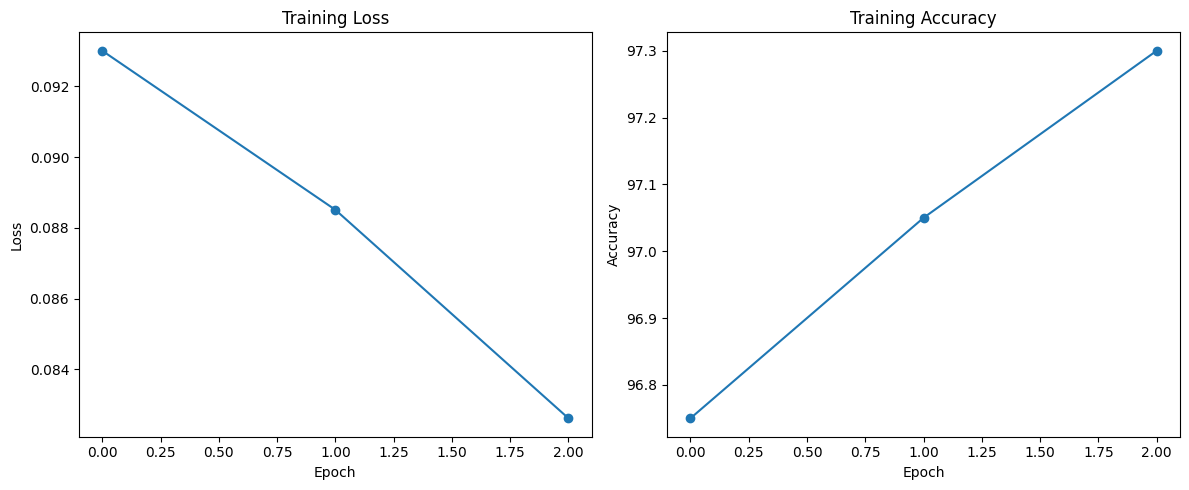

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, marker='o')
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

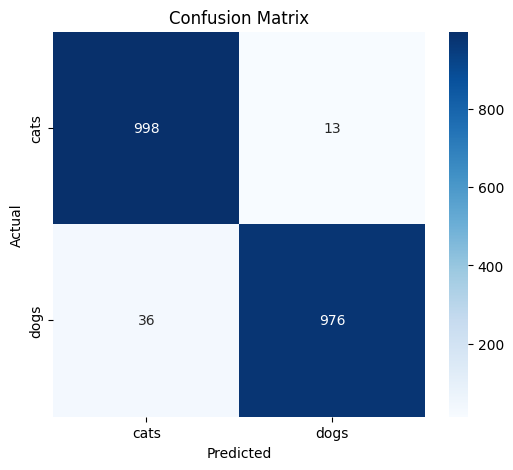

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
torch.save(
    model.state_dict(),
    "cats_dogs_resnet18.pth"
)

print("Model Saved Successfully!")

Model Saved Successfully!
